# Practical CNN: From Convolution Mechanics to Fine-Tuning

**Estimated class time:** about 120 minutes  
**Environment:** Google Colab Free (CPU works; a free GPU is recommended when available)  
**Framework:** PyTorch / TorchVision

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain what a convolution kernel does at one image location.
2. Visualize how the same kernel is reused across an image.
3. Explain **local connectivity**, **weight sharing**, **feature maps**, **ReLU**, and **pooling**.
4. Trace tensor shapes through a small CNN.
5. Fine-tune a pretrained CNN on a small image dataset.
6. Evaluate the model using **accuracy, precision, recall, macro-F1, weighted-F1, and a confusion matrix**.
7. Measure model complexity using **parameter count, GMACs, approximate GFLOPs, model size, and inference latency**.
8. Inspect learned feature maps and model failure cases.

---

## The main idea

A CNN does not connect every output unit to every image pixel.

Instead, it repeatedly applies small learnable filters to local regions:

\[
\text{image}
\rightarrow
\text{local filters}
\rightarrow
\text{feature maps}
\rightarrow
\text{deeper features}
\rightarrow
\text{classifier}
\]

The important architectural bias is:

> **A useful local pattern may appear at many positions, so the same filter should be reusable across the image.**

This notebook first makes that mechanism visible, then uses the same idea inside a real pretrained CNN.

## Session map

| Part | Topic | Approx. time |
|---|---|---:|
| 0 | Setup and reproducibility | 10 min |
| 1 | Convolution by hand | 20 min |
| 2 | Filters, ReLU, pooling, and feature maps | 25 min |
| 3 | Small CNN and tensor shapes | 15 min |
| 4 | Transfer learning and fine-tuning | 30 min |
| 5 | Metrics, FLOPs, latency, and failure analysis | 15 min |
| 6 | Exercises | 5+ min |

The notebook uses a **small balanced subset of four CIFAR-10 classes** so that training remains practical on free Colab.

In [ ]:
# Install only the small extra package used for MAC/FLOP profiling.
# Do NOT upgrade torch/torchvision in Colab; using the preinstalled compatible pair is safer.
%pip -q install ultralytics-thop

In [ ]:
import copy
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
)

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU mode is supported. Training will simply be slower.")

PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
Device: cuda
GPU: Tesla T4


For a single-channel image, a $3\times3$ convolution kernel has only nine weights.

At one location:

$$
y_{i,j}
=
\sum_{u=0}^{2}\sum_{v=0}^{2}
x_{i+u,j+v}k_{u,v}
+b
$$

For now, we set the bias to zero.

A vertical-edge kernel can be written as:

$$
K=
\begin{bmatrix}
-1&0&1\\
-1&0&1\\
-1&0&1
\end{bmatrix}
$$

Large positive or negative responses indicate a strong left-right intensity change in the local patch.

**Important:** in a real CNN, kernels are usually **learned from data**. We manually choose a kernel here only so that its behavior is easy to see.

In [ ]:
x2d = torch.tensor([
    [1., 1., 1., 8., 8., 8.],
    [1., 1., 1., 8., 8., 8.],
    [1., 1., 1., 8., 8., 8.],
    [1., 1., 2., 7., 8., 8.],
    [1., 1., 2., 7., 8., 8.],
    [1., 1., 2., 7., 8., 8.],
])

kernel2d = torch.tensor([
    [-1., 0., 1.],
    [-1., 0., 1.],
    [-1., 0., 1.],
])

# conv2d expects NCHW:
# N=batch, C=channel, H=height, W=width
x = x2d[None, None, :, :]
kernel = kernel2d[None, None, :, :]

feature_map = F.conv2d(x, kernel, stride=1, padding=0)

print("Input shape:      ", tuple(x.shape))
print("Kernel shape:     ", tuple(kernel.shape))
print("Feature map shape:", tuple(feature_map.shape))
print("\nFeature map:\n", feature_map[0, 0])

Input shape:       (1, 1, 6, 6)
Kernel shape:      (1, 1, 3, 3)
Feature map shape: (1, 1, 4, 4)

Feature map:
 tensor([[ 0., 21., 21.,  0.],
        [ 1., 20., 20.,  1.],
        [ 2., 19., 19.,  2.],
        [ 3., 18., 18.,  3.]])


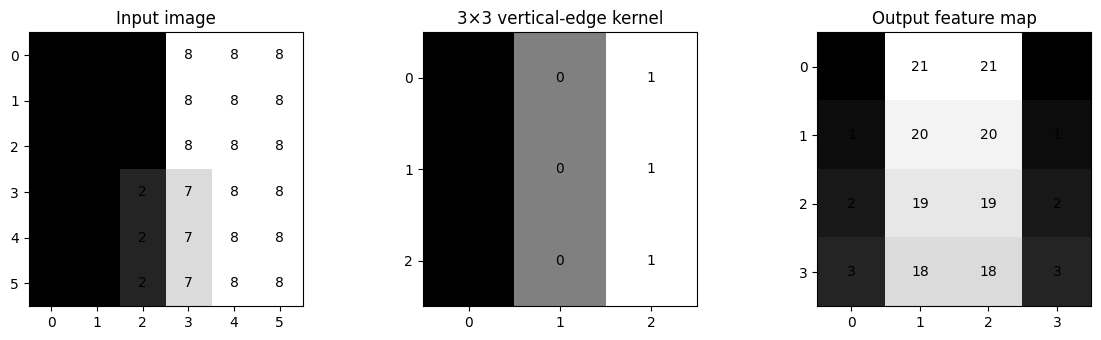

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

items = [
    (x2d.numpy(), "Input image"),
    (kernel2d.numpy(), "3×3 vertical-edge kernel"),
    (feature_map[0, 0].detach().numpy(), "Output feature map"),
]

for ax, (arr, title) in zip(axes, items):
    ax.imshow(arr, cmap="gray")
    ax.set_title(title)
    ax.set_xticks(range(arr.shape[1]))
    ax.set_yticks(range(arr.shape[0]))

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            ax.text(j, i, f"{arr[i, j]:.0f}", ha="center", va="center")

plt.tight_layout()
plt.show()

## 1.2 Verify one output value manually

The output at location $(i,j)$ comes from exactly one local patch.

$$
\text{output}
=
\sum(\text{patch}\odot\text{kernel})
$$

where $\odot$ means element-wise multiplication.

In [ ]:
row, col = 1, 2

patch = x2d[row:row+3, col:col+3]
products = patch * kernel2d
manual_value = products.sum()
torch_value = feature_map[0, 0, row, col]

print("Selected patch:\n", patch)
print("\nPatch × kernel:\n", products)
print("\nManual sum:", manual_value.item())
print("PyTorch conv2d value:", torch_value.item())

assert torch.allclose(manual_value, torch_value)
print("\nCheck passed: the manual computation equals Conv2d.")

Selected patch:
 tensor([[1., 8., 8.],
        [1., 8., 8.],
        [2., 7., 8.]])

Patch × kernel:
 tensor([[-1.,  0.,  8.],
        [-1.,  0.,  8.],
        [-2.,  0.,  8.]])

Manual sum: 20.0
PyTorch conv2d value: 20.0

Check passed: the manual computation equals Conv2d.


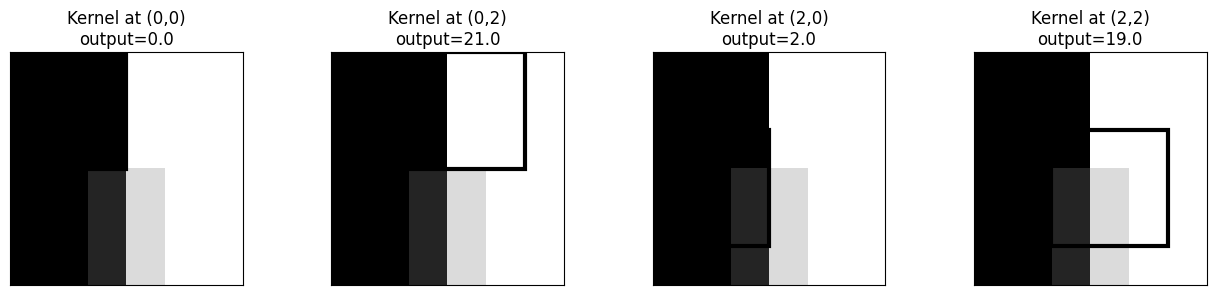

The weights did not change between positions.
This reuse of the same weights is called WEIGHT SHARING.


In [ ]:
from matplotlib.patches import Rectangle

positions = [(0, 0), (0, 2), (2, 0), (2, 2)]

fig, axes = plt.subplots(1, len(positions), figsize=(13, 3))

for ax, (r, c) in zip(axes, positions):
    ax.imshow(x2d.numpy(), cmap="gray")
    ax.add_patch(Rectangle((c - 0.5, r - 0.5), 3, 3, fill=False, linewidth=3))
    value = feature_map[0, 0, r, c].item()
    ax.set_title(f"Kernel at ({r},{c})\noutput={value:.1f}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

print("The weights did not change between positions.")
print("This reuse of the same weights is called WEIGHT SHARING.")

## 1.3 Why weight sharing matters

Suppose an RGB image has shape $224\times224\times3$.

A dense layer from all pixels to 256 neurons would require roughly:

$$
224\times224\times3\times256
$$

weights.

A convolution from 3 input channels to 32 output channels using $3\times3$ kernels requires:

$$
32\times3\times3\times3
$$

weights, plus 32 biases.

In [ ]:
dense_weights = 224 * 224 * 3 * 256
conv_weights = 32 * 3 * 3 * 3
conv_biases = 32

print(f"Dense weights: {dense_weights:,}")
print(f"Conv weights:  {conv_weights:,}")
print(f"Conv + bias:   {conv_weights + conv_biases:,}")
print(f"Weight ratio (dense / conv): {dense_weights / (conv_weights + conv_biases):,.0f}×")

Dense weights: 38,535,168
Conv weights:  864
Conv + bias:   896
Weight ratio (dense / conv): 43,008×


# Part 2 — Filters, ReLU, pooling, and feature maps

A CNN layer usually contains **many filters**.

Each filter produces one output channel (one feature map).

In early layers, filters often respond to simple patterns such as edges, directions, texture, or contrast. Deeper layers combine earlier features into more complex representations.

We first use hand-written filters because they are interpretable.

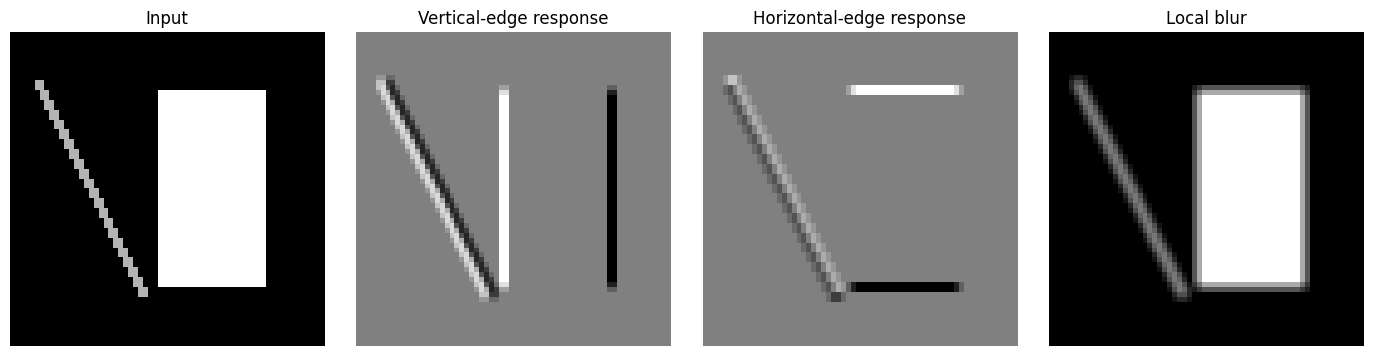

In [ ]:
img = np.zeros((64, 64), dtype=np.float32)

# Bright rectangle.
img[12:52, 30:52] = 1.0

# A diagonal bright line.
for i in range(10, 54):
    j = i // 2
    img[i, j:j+2] = 0.7

img_tensor = torch.tensor(img)[None, None]

vertical = torch.tensor([
    [-1., 0., 1.],
    [-2., 0., 2.],
    [-1., 0., 1.],
])[None, None]

horizontal = torch.tensor([
    [-1., -2., -1.],
    [ 0.,  0.,  0.],
    [ 1.,  2.,  1.],
])[None, None]

blur = torch.ones((1, 1, 3, 3)) / 9.0

filters = {
    "Input": None,
    "Vertical-edge response": vertical,
    "Horizontal-edge response": horizontal,
    "Local blur": blur,
}

outputs = {}
for name, filt in filters.items():
    if filt is None:
        outputs[name] = img_tensor[0, 0]
    else:
        outputs[name] = F.conv2d(img_tensor, filt, padding=1)[0, 0]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (name, arr) in zip(axes, outputs.items()):
    ax.imshow(arr.detach().numpy(), cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.1 ReLU keeps the network nonlinear

Convolution itself is a linear operation with respect to the input.

A common next step is ReLU:

$$
\operatorname{ReLU}(z)=\max(0,z)
$$

Without nonlinear activation functions, stacking many linear layers would still collapse into a single linear transformation.

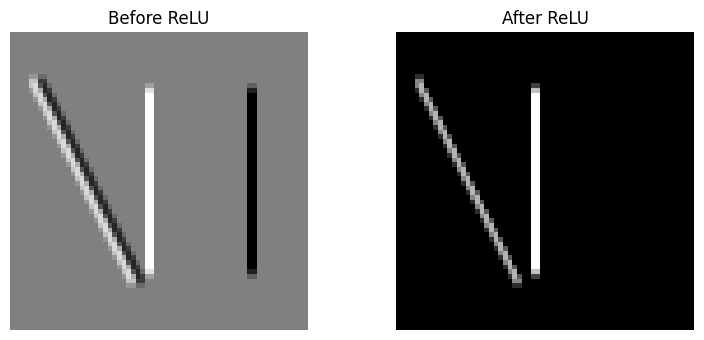

Before ReLU: min = -4.0 max = 4.0
After ReLU:  min = 0.0 max = 4.0


In [ ]:
edge = outputs["Vertical-edge response"]
relu_edge = F.relu(edge)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(edge.numpy(), cmap="gray")
axes[0].set_title("Before ReLU")
axes[0].axis("off")

axes[1].imshow(relu_edge.numpy(), cmap="gray")
axes[1].set_title("After ReLU")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Before ReLU: min =", float(edge.min()), "max =", float(edge.max()))
print("After ReLU:  min =", float(relu_edge.min()), "max =", float(relu_edge.max()))

## 2.2 Pooling reduces spatial resolution

For max pooling:

$$
y_{i,j}
=
\max(\text{local window})
$$

A $2\times2$ max-pooling layer with stride 2 approximately halves height and width.

Pooling is **not the definition of a CNN**. Modern CNNs may also downsample using strided convolutions.

Before pooling: (1, 1, 64, 64)
After pooling:  (1, 1, 32, 32)


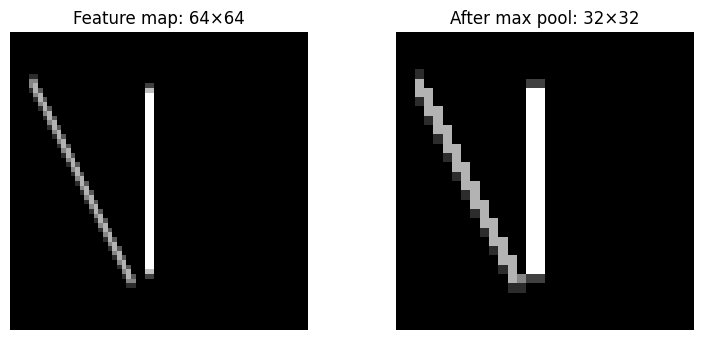

In [ ]:
demo_feature = relu_edge[None, None]
pooled = F.max_pool2d(demo_feature, kernel_size=2, stride=2)

print("Before pooling:", tuple(demo_feature.shape))
print("After pooling: ", tuple(pooled.shape))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(demo_feature[0, 0].numpy(), cmap="gray")
axes[0].set_title("Feature map: 64×64")
axes[0].axis("off")

axes[1].imshow(pooled[0, 0].numpy(), cmap="gray")
axes[1].set_title("After max pool: 32×32")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 2.3 Stride and padding control output shape

For one spatial dimension:

$$
N_{\text{out}}
=
\left\lfloor
\frac{N+2P-K}{S}
\right\rfloor+1
$$

where $N$ is input size, $K$ kernel size, $P$ padding, and $S$ stride.

In [ ]:
def conv_output_size(n, kernel_size, padding, stride):
    return math.floor((n + 2 * padding - kernel_size) / stride) + 1

examples = [
    (32, 3, 0, 1),
    (32, 3, 1, 1),
    (32, 3, 1, 2),
    (64, 5, 2, 1),
]

rows = []
for n, k, p, s in examples:
    rows.append({
        "Input N": n,
        "Kernel K": k,
        "Padding P": p,
        "Stride S": s,
        "Output N": conv_output_size(n, k, p, s),
    })

pd.DataFrame(rows)

,Input N,Kernel K,Padding P,Stride S,Output N
0,32,3,0,1,30
1,32,3,1,1,32
2,32,3,1,2,16
3,64,5,2,1,64


# Part 3 — Trace shapes through a small CNN

A real image tensor is usually stored as:

$$
(N,C,H,W)
$$

For RGB images, $C=3$.

The example below is intentionally small. Its purpose is to make data flow visible, not to achieve high accuracy.

In [ ]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(16, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


tiny_model = TinyCNN(num_classes=4)
dummy = torch.randn(2, 3, 32, 32)

shape_log = []

def make_hook(name):
    def hook(module, inputs, output):
        shape_log.append((name, tuple(output.shape)))
    return hook

hooks = []
for name, module in tiny_model.named_modules():
    if isinstance(module, (nn.Conv2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear)):
        hooks.append(module.register_forward_hook(make_hook(name)))

with torch.no_grad():
    tiny_logits = tiny_model(dummy)

for h in hooks:
    h.remove()

print("Input:", tuple(dummy.shape))
for name, shape in shape_log:
    print(f"{name:15s} -> {shape}")
print("Final logits:", tuple(tiny_logits.shape))

Input: (2, 3, 32, 32)
features.0      -> (2, 8, 32, 32)
features.2      -> (2, 8, 16, 16)
features.3      -> (2, 16, 16, 16)
features.5      -> (2, 16, 8, 8)
pool            -> (2, 16, 1, 1)
classifier      -> (2, 4)
Final logits: (2, 4)


### Read the shapes, not just the code

```text
2 × 3 × 32 × 32
→ 2 × 8 × 32 × 32
→ 2 × 8 × 16 × 16
→ 2 × 16 × 16 × 16
→ 2 × 16 × 8 × 8
→ 2 × 16 × 1 × 1
→ 2 × 4 logits
```

The spatial dimensions shrink while the number of learned feature channels grows.

# Part 4 — Fine-tune a pretrained CNN

## 4.1 Why transfer learning?

Training a strong vision model from random initialization usually requires more data and compute.

Transfer learning starts from features learned on a large source dataset and adapts them to a new task.

We use **MobileNetV3-Small pretrained on ImageNet-1K** because it is a real modern CNN, lightweight, officially supported by TorchVision, and suitable for a free Colab exercise.

We fine-tune it on four CIFAR-10 classes:

- airplane
- automobile
- cat
- dog

In [ ]:
IMAGE_SIZE = 128

SELECTED_CLASS_IDS = [0, 1, 3, 5]
SELECTED_CLASS_NAMES = ["airplane", "automobile", "cat", "dog"]

TRAIN_PER_CLASS = 500
VAL_PER_CLASS = 100
TEST_PER_CLASS = 200

BATCH_SIZE = 64 if device.type == "cuda" else 32

HEAD_EPOCHS = 1
FINETUNE_EPOCHS = 2

print("Classes:", SELECTED_CLASS_NAMES)
print("Train images:", TRAIN_PER_CLASS * len(SELECTED_CLASS_IDS))
print("Validation images:", VAL_PER_CLASS * len(SELECTED_CLASS_IDS))
print("Test images:", TEST_PER_CLASS * len(SELECTED_CLASS_IDS))
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Classes: ['airplane', 'automobile', 'cat', 'dog']
Train images: 2000
Validation images: 400
Test images: 800
Image size: 128
Batch size: 64


## 4.2 Preprocessing

CIFAR-10 images are only $32\times32$, while ImageNet-pretrained models were trained with larger images.

For this compact exercise, we resize to $128\times128$ to reduce compute while preserving the transfer-learning workflow.

We keep ImageNet normalization:

$$
\mu=[0.485,0.456,0.406]
$$

$$
\sigma=[0.229,0.224,0.225]
$$

Training gets light augmentation. Validation and test do not.

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(IMAGE_SIZE, padding=8, padding_mode="reflect"),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

raw_train = datasets.CIFAR10(root="./data", train=True, download=True)
raw_test = datasets.CIFAR10(root="./data", train=False, download=True)

print("Full CIFAR-10 train:", len(raw_train))
print("Full CIFAR-10 test: ", len(raw_test))
print("Original classes:", raw_train.classes)

100%|██████████| 170M/170M [37:29<00:00, 75.8kB/s]


Full CIFAR-10 train: 50000
Full CIFAR-10 test:  10000
Original classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
def make_train_val_indices(targets, class_ids, train_per_class, val_per_class, seed=42):
    targets = np.asarray(targets)
    rng = np.random.default_rng(seed)

    train_idx = []
    val_idx = []

    for class_id in class_ids:
        idx = np.flatnonzero(targets == class_id)
        rng.shuffle(idx)

        required = train_per_class + val_per_class
        if len(idx) < required:
            raise ValueError(f"Class {class_id} has only {len(idx)} examples; need {required}.")

        train_idx.extend(idx[:train_per_class].tolist())
        val_idx.extend(idx[train_per_class:required].tolist())

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    return train_idx, val_idx


def make_test_indices(targets, class_ids, test_per_class, seed=43):
    targets = np.asarray(targets)
    rng = np.random.default_rng(seed)

    test_idx = []

    for class_id in class_ids:
        idx = np.flatnonzero(targets == class_id)
        rng.shuffle(idx)

        if len(idx) < test_per_class:
            raise ValueError(f"Class {class_id} has only {len(idx)} examples; need {test_per_class}.")

        test_idx.extend(idx[:test_per_class].tolist())

    rng.shuffle(test_idx)
    return test_idx


train_indices, val_indices = make_train_val_indices(
    raw_train.targets,
    SELECTED_CLASS_IDS,
    TRAIN_PER_CLASS,
    VAL_PER_CLASS,
    seed=SEED,
)

test_indices = make_test_indices(
    raw_test.targets,
    SELECTED_CLASS_IDS,
    TEST_PER_CLASS,
    seed=SEED + 1,
)

print(len(train_indices), len(val_indices), len(test_indices))
print("Train/val overlap:", len(set(train_indices).intersection(val_indices)))

2000 400 800
Train/val overlap: 0


In [ ]:
class RemappedSubset(Dataset):
    # Subset a dataset and remap original labels to 0..K-1.
    def __init__(self, base_dataset, indices, label_map):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.label_map = dict(label_map)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, original_label = self.base_dataset[self.indices[i]]
        return x, self.label_map[original_label]


label_map = {
    original_id: new_id
    for new_id, original_id in enumerate(SELECTED_CLASS_IDS)
}

train_base = datasets.CIFAR10(root="./data", train=True, transform=train_transform, download=False)
val_base = datasets.CIFAR10(root="./data", train=True, transform=eval_transform, download=False)
test_base = datasets.CIFAR10(root="./data", train=False, transform=eval_transform, download=False)

train_ds = RemappedSubset(train_base, train_indices, label_map)
val_ds = RemappedSubset(val_base, val_indices, label_map)
test_ds = RemappedSubset(test_base, test_indices, label_map)

num_workers = 2 if device.type == "cuda" else 0

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=(device.type == "cuda"),
)

xb, yb = next(iter(train_loader))
print("Batch images:", tuple(xb.shape))
print("Batch labels:", tuple(yb.shape))
print("Label range:", int(yb.min()), "to", int(yb.max()))

Batch images: (64, 3, 128, 128)
Batch labels: (64,)
Label range: 0 to 3


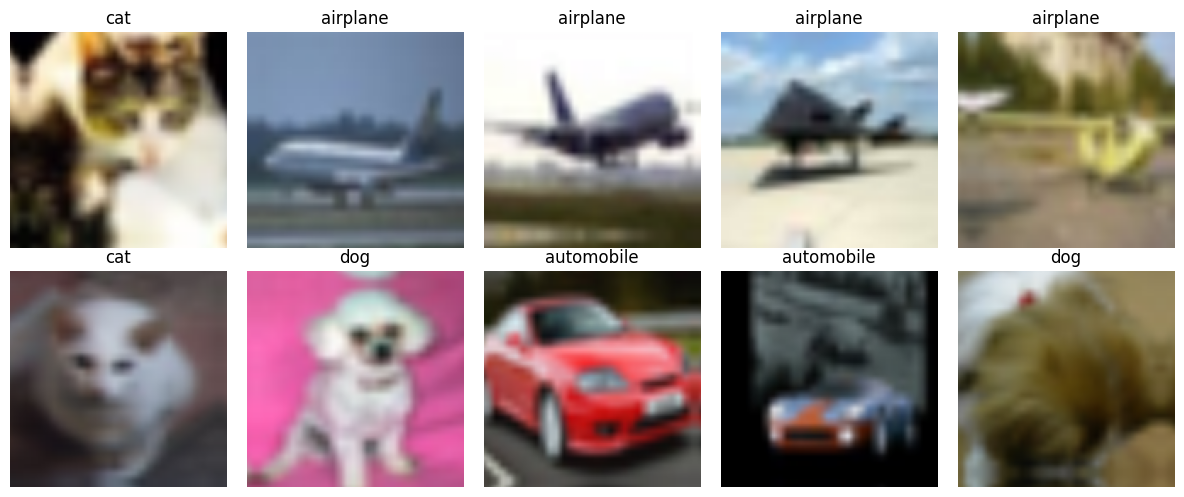

In [ ]:
mean_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_t = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denormalize(image_tensor):
    return (image_tensor.cpu() * std_t + mean_t).clamp(0, 1)


images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    img_show = denormalize(image).permute(1, 2, 0).numpy()
    ax.imshow(img_show)
    ax.set_title(SELECTED_CLASS_NAMES[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4.3 Build the pretrained model

The original MobileNetV3-Small classifier predicts 1000 ImageNet classes.

We replace the final linear layer with a new 4-class layer.

### Phase A — train only the new classifier

The pretrained convolutional backbone is frozen.

### Phase B — fine-tune the final feature blocks

We unfreeze only the last few backbone blocks and use a smaller learning rate for them.

In [ ]:
weights = MobileNet_V3_Small_Weights.DEFAULT
model = mobilenet_v3_small(weights=weights)

for p in model.parameters():
    p.requires_grad = False

in_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(in_features, len(SELECTED_CLASS_NAMES))

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model.classifier)
print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Trainable fraction:   {100 * trainable_params / total_params:.2f}%")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 97.6MB/s]

Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=4, bias=True)
)

Total parameters:     1,521,956
Trainable parameters: 4,100
Trainable fraction:   0.27%


### Small-data detail: frozen BatchNorm should stay frozen

Calling `model.train()` changes BatchNorm layers to training mode, even when their weights are frozen. That can still update their running mean and variance.

The helper below keeps BatchNorm layers inside frozen blocks in evaluation mode. When a block is later unfrozen, its BatchNorm parameters become trainable again and the layer can update normally.

In [ ]:
criterion = nn.CrossEntropyLoss()

def keep_frozen_batchnorm_in_eval(model):
    # model.train() would normally switch every BatchNorm layer to training mode.
    # For frozen blocks, we keep BatchNorm running statistics fixed.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            params = list(module.parameters())
            if params and not any(p.requires_grad for p in params):
                module.eval()


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    if training:
        keep_frozen_batchnorm_in_eval(model)

    running_loss = 0.0
    all_targets = []
    all_preds = []

    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        logits = model(xb)
        loss = criterion(logits, yb)

        if training:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * xb.size(0)

        preds = logits.argmax(dim=1)
        all_targets.extend(yb.detach().cpu().tolist())
        all_preds.extend(preds.detach().cpu().tolist())

    loss_value = running_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)

    return {
        "loss": loss_value,
        "accuracy": acc,
        "macro_f1": macro_f1,
    }


@torch.no_grad()
def predict_loader(model, loader):
    model.eval()

    all_targets = []
    all_preds = []
    all_probs = []

    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        probs = logits.softmax(dim=1)
        preds = probs.argmax(dim=1)

        all_targets.extend(yb.tolist())
        all_preds.extend(preds.cpu().tolist())
        all_probs.extend(probs.cpu().numpy())

    return (
        np.asarray(all_targets),
        np.asarray(all_preds),
        np.asarray(all_probs),
    )

## 4.4 Phase A — train the new head

Only the **new 4-class output layer** is trainable; all pretrained parameters remain frozen.

We use validation **macro-F1** as the checkpoint criterion.

Macro-F1 computes F1 separately for every class and averages them equally.

In [ ]:
history = []
best_val_f1 = -1.0
best_state = copy.deepcopy(model.state_dict())

head_optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=3e-3,
    weight_decay=1e-4,
)

for epoch in range(1, HEAD_EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, optimizer=head_optimizer)
    val_metrics = run_epoch(model, val_loader, optimizer=None)

    row = {
        "phase": "head",
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    }
    history.append(row)

    print(
        f"[Head] Epoch {epoch:02d} | "
        f"train loss={row['train_loss']:.4f}, "
        f"train F1={row['train_macro_f1']:.3f} | "
        f"val loss={row['val_loss']:.4f}, "
        f"val F1={row['val_macro_f1']:.3f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_state = copy.deepcopy(model.state_dict())

[Head] Epoch 01 | train loss=0.5017, train F1=0.810 | val loss=0.3806, val F1=0.858


## 4.5 Phase B — unfreeze the last feature blocks

Now we unfreeze the final three feature blocks **and the classifier block**.

We use:

- a small learning rate for pretrained backbone weights;
- a larger learning rate for the task-specific classifier.

In [ ]:
# Fine-tune the final convolutional blocks.
for block in model.features[-3:]:
    for p in block.parameters():
        p.requires_grad = True

# In Phase B, allow the classifier block to adapt as well.
for p in model.classifier.parameters():
    p.requires_grad = True

backbone_params = [p for p in model.features.parameters() if p.requires_grad]
head_params = [p for p in model.classifier.parameters() if p.requires_grad]

finetune_optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-4},
        {"params": head_params, "lr": 5e-4},
    ],
    weight_decay=1e-4,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters after unfreezing: {trainable_params:,}")

Trainable parameters after unfreezing: 1,239,588


In [ ]:
for epoch in range(1, FINETUNE_EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, optimizer=finetune_optimizer)
    val_metrics = run_epoch(model, val_loader, optimizer=None)

    row = {
        "phase": "fine-tune",
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    }
    history.append(row)

    print(
        f"[Fine-tune] Epoch {epoch:02d} | "
        f"train loss={row['train_loss']:.4f}, "
        f"train F1={row['train_macro_f1']:.3f} | "
        f"val loss={row['val_loss']:.4f}, "
        f"val F1={row['val_macro_f1']:.3f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
print(f"\nBest validation macro-F1: {best_val_f1:.4f}")

[Fine-tune] Epoch 01 | train loss=0.3816, train F1=0.840 | val loss=0.4112, val F1=0.840
[Fine-tune] Epoch 02 | train loss=0.2447, train F1=0.906 | val loss=0.4245, val F1=0.834

Best validation macro-F1: 0.8579


In [ ]:
history_df = pd.DataFrame(history)
history_df

,phase,epoch,train_loss,train_acc,train_macro_f1,val_loss,val_acc,val_macro_f1
0,head,1,0.501725,0.8100,0.809886,0.380618,0.8575,0.857922
1,fine-tune,1,0.381644,0.8395,0.839771,0.411167,0.8425,0.840000
2,fine-tune,2,0.244664,0.9065,0.906411,0.424455,0.8375,0.833722


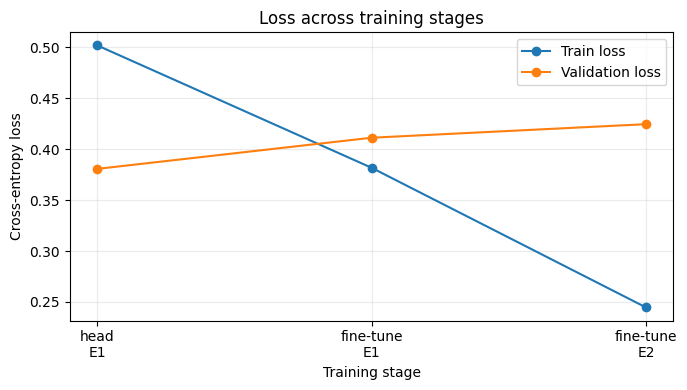

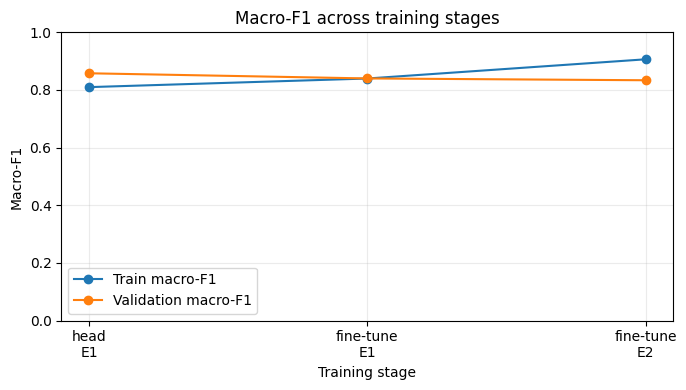

In [ ]:
steps = np.arange(1, len(history_df) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps, history_df["train_loss"], marker="o", label="Train loss")
ax.plot(steps, history_df["val_loss"], marker="o", label="Validation loss")
ax.set_xlabel("Training stage")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Loss across training stages")
ax.set_xticks(steps)
ax.set_xticklabels(
    [f"{p}\nE{e}" for p, e in zip(history_df["phase"], history_df["epoch"])]
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps, history_df["train_macro_f1"], marker="o", label="Train macro-F1")
ax.plot(steps, history_df["val_macro_f1"], marker="o", label="Validation macro-F1")
ax.set_xlabel("Training stage")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Macro-F1 across training stages")
ax.set_xticks(steps)
ax.set_xticklabels(
    [f"{p}\nE{e}" for p, e in zip(history_df["phase"], history_df["epoch"])]
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Part 5 — Final evaluation

## 5.1 Evaluate the test set once

The test set should not be used for choosing epochs, learning rates, augmentation, layers to unfreeze, or checkpoints.

Those choices belong to training + validation.

Now that training decisions are finished, we evaluate the test set once.

In [ ]:
y_true, y_pred, y_prob = predict_loader(model, test_loader)

accuracy = accuracy_score(y_true, y_pred)

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

_, _, f1_weighted, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

summary_metrics = pd.DataFrame([{
    "accuracy": accuracy,
    "macro_precision": precision_macro,
    "macro_recall": recall_macro,
    "macro_f1": f1_macro,
    "weighted_f1": f1_weighted,
}])

summary_metrics

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,0.855,0.856626,0.855,0.855445,0.855445


In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=SELECTED_CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T
report_df

,precision,recall,f1-score,support
airplane,0.908629,0.895,0.901763,200.000
automobile,0.949749,0.945,0.947368,200.000
cat,0.752336,0.805,0.777778,200.000
dog,0.815789,0.775,0.794872,200.000
accuracy,0.855000,0.855,0.855000,0.855
macro avg,0.856626,0.855,0.855445,800.000
weighted avg,0.856626,0.855,0.855445,800.000


### Accuracy and F1 answer different questions

$$
\text{Accuracy}
=
\frac{\text{correct predictions}}{\text{samples}}
$$

$$
\text{Precision}
=
\frac{TP}{TP+FP}
$$

$$
\text{Recall}
=
\frac{TP}{TP+FN}
$$

$$
F_1
=
2\frac{\text{Precision}\cdot\text{Recall}}
{\text{Precision}+\text{Recall}}
$$

**Macro-F1** averages class F1 values equally.

**Weighted-F1** weights each class by its support.

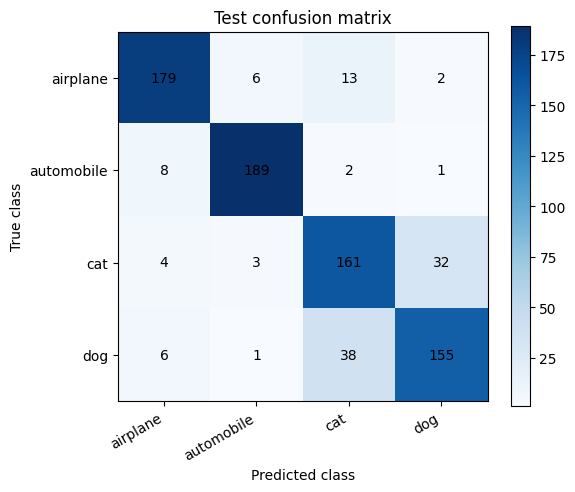

In [ ]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(len(SELECTED_CLASS_NAMES)))
ax.set_yticks(range(len(SELECTED_CLASS_NAMES)))
ax.set_xticklabels(SELECTED_CLASS_NAMES, rotation=30, ha="right")
ax.set_yticklabels(SELECTED_CLASS_NAMES)

ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Test confusion matrix")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 5.2 Computational cost: parameters, GMACs, and GFLOPs

- **Parameters** measure learned values stored by the model.
- **MACs** count multiply-accumulate operations.
- **FLOPs** count floating-point operations.

Different tools use different conventions.

Here we additionally report:

$$
\text{approx. FLOPs}\approx2\times\text{MACs}
$$

because one multiply-accumulate is treated as one multiplication plus one addition.

Therefore, compare FLOP values only when the profiler, input size, and counting convention are the same.

Also:

> **FLOPs are not latency.**

In [ ]:
from thop import profile

profile_model = copy.deepcopy(model).cpu().eval()
dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)

macs, thop_params = profile(
    profile_model,
    inputs=(dummy_input,),
    verbose=False,
)

gmacs = macs / 1e9
approx_gflops = 2 * macs / 1e9

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

complexity_df = pd.DataFrame([{
    "input": f"1×3×{IMAGE_SIZE}×{IMAGE_SIZE}",
    "parameters_M": total_params / 1e6,
    "trainable_parameters_M": trainable_params / 1e6,
    "GMACs": gmacs,
    "approx_GFLOPs_2xMAC": approx_gflops,
}])

complexity_df

,input,parameters_M,trainable_parameters_M,GMACs,approx_GFLOPs_2xMAC
0,1×3×128×128,1.521956,1.239588,0.020779,0.041558


In [ ]:
checkpoint_path = Path("mobilenetv3_cifar4_best_state.pt")
torch.save({k: v.cpu() for k, v in model.state_dict().items()}, checkpoint_path)

size_mb = checkpoint_path.stat().st_size / (1024 ** 2)
print(f"Checkpoint size: {size_mb:.2f} MB")

Checkpoint size: 5.93 MB


## 5.3 Measure batch-1 inference latency

Latency depends on the current hardware.

We use warm-up passes, synchronize CUDA when needed, and report median/mean latency.

This is an educational benchmark, not a production benchmark.

In [ ]:
def synchronize_if_needed():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def measure_latency(model, image_size=128, warmup=10, repeats=50):
    model.eval()
    x = torch.randn(1, 3, image_size, image_size, device=device)

    for _ in range(warmup):
        _ = model(x)

    synchronize_if_needed()

    times_ms = []
    for _ in range(repeats):
        synchronize_if_needed()
        start = time.perf_counter()

        _ = model(x)

        synchronize_if_needed()
        end = time.perf_counter()
        times_ms.append((end - start) * 1000)

    return np.asarray(times_ms)


latencies = measure_latency(model, IMAGE_SIZE)

latency_df = pd.DataFrame([{
    "device": str(device),
    "batch_size": 1,
    "input_size": IMAGE_SIZE,
    "median_ms": np.median(latencies),
    "mean_ms": np.mean(latencies),
    "p90_ms": np.percentile(latencies, 90),
}])

latency_df

,device,batch_size,input_size,median_ms,mean_ms,p90_ms
0,cuda,1,128,7.306233,7.694582,9.414615


In [ ]:
final_summary = pd.DataFrame([{
    "model": "MobileNetV3-Small fine-tuned",
    "test_accuracy": accuracy,
    "test_macro_f1": f1_macro,
    "params_M": total_params / 1e6,
    "GMACs": gmacs,
    "approx_GFLOPs_2xMAC": approx_gflops,
    "checkpoint_MB": size_mb,
    "median_latency_ms": np.median(latencies),
    "device": str(device),
}])

final_summary

,model,test_accuracy,test_macro_f1,params_M,GMACs,approx_GFLOPs_2xMAC,checkpoint_MB,median_latency_ms,device
0,MobileNetV3-Small fine-tuned,0.855,0.855445,1.521956,0.020779,0.041558,5.926776,7.306233,cuda


# Part 6 — What did the CNN actually learn?

The model is no longer using our manually designed edge filters.

Its convolutional filters were learned on ImageNet and then partially adapted to our task.

An internal activation map answers:

> For this input image, where does one learned channel respond strongly?

Do not interpret every channel as a clean human concept. Learned representations can be distributed.

In [ ]:
sample_x, sample_y = test_ds[0]
sample_batch = sample_x.unsqueeze(0).to(device)

activations = {}

def save_activation(name):
    def hook(module, inputs, output):
        activations[name] = output.detach().cpu()
    return hook

hook_early = model.features[0].register_forward_hook(save_activation("early"))
hook_late = model.features[-3].register_forward_hook(save_activation("late"))

model.eval()
with torch.no_grad():
    logits = model(sample_batch)
    pred = logits.argmax(dim=1).item()
    confidence = logits.softmax(dim=1).max().item()

hook_early.remove()
hook_late.remove()

print("True class:", SELECTED_CLASS_NAMES[sample_y])
print("Predicted :", SELECTED_CLASS_NAMES[pred])
print("Confidence:", f"{confidence:.3f}")
print("Early activation shape:", tuple(activations["early"].shape))
print("Later activation shape:", tuple(activations["late"].shape))

True class: cat
Predicted : dog
Confidence: 0.652
Early activation shape: (1, 16, 64, 64)
Later activation shape: (1, 96, 4, 4)


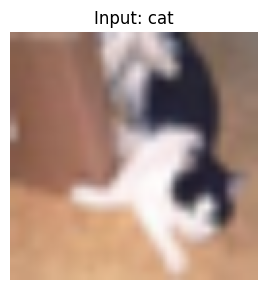

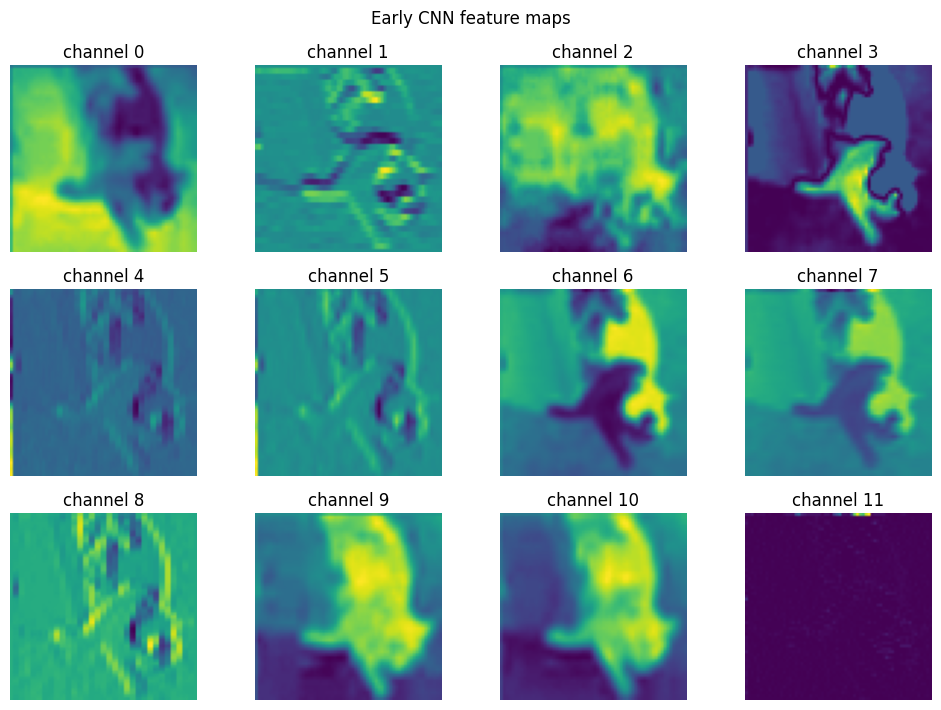

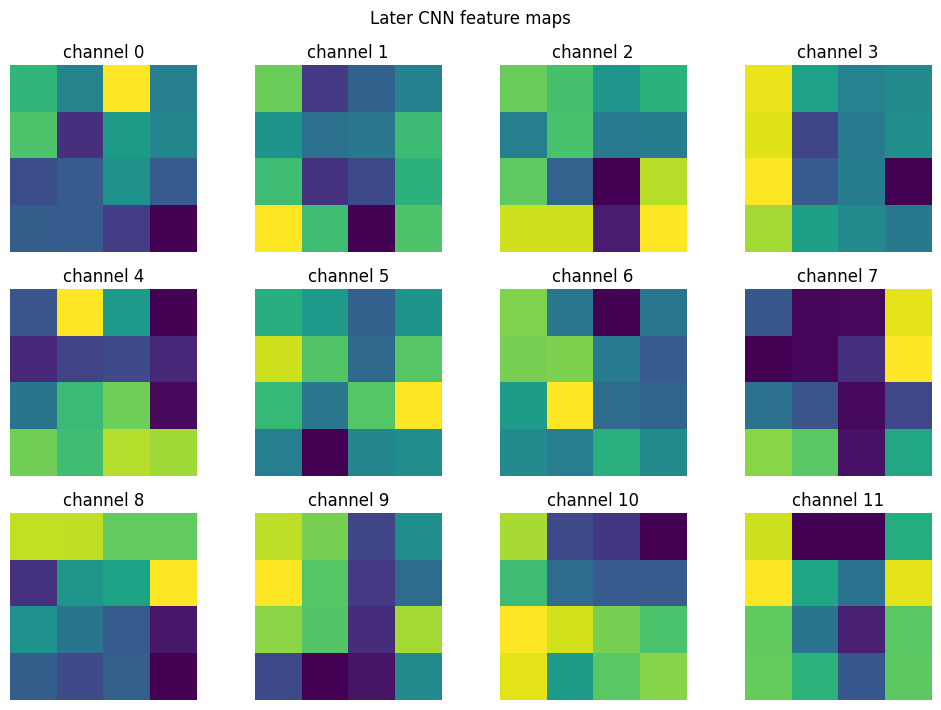

In [ ]:
def show_feature_maps(feature_tensor, title, max_maps=12):
    fmap = feature_tensor[0]
    n = min(max_maps, fmap.shape[0])

    cols = 4
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.4 * rows))
    axes = np.atleast_1d(axes).ravel()

    for i in range(n):
        axes[i].imshow(fmap[i].numpy(), cmap="viridis")
        axes[i].set_title(f"channel {i}")
        axes[i].axis("off")

    for i in range(n, len(axes)):
        axes[i].axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(denormalize(sample_x).permute(1, 2, 0).numpy())
ax.set_title(f"Input: {SELECTED_CLASS_NAMES[sample_y]}")
ax.axis("off")
plt.tight_layout()
plt.show()

show_feature_maps(activations["early"], "Early CNN feature maps")
show_feature_maps(activations["late"], "Later CNN feature maps")

### What should you notice?

Early feature maps usually preserve more spatial detail.

Later feature maps:

- have lower spatial resolution;
- have more channels;
- combine information from larger effective receptive fields;
- are closer to the final classification decision.

```text
pixels
→ local responses
→ repeated convolutional blocks
→ larger-context features
→ global pooling
→ class logits
```

# Part 7 — Failure analysis

A confusion matrix tells us **which classes are confused overall**.

Individual errors show **what those failures look like**.

Number of test errors: 116


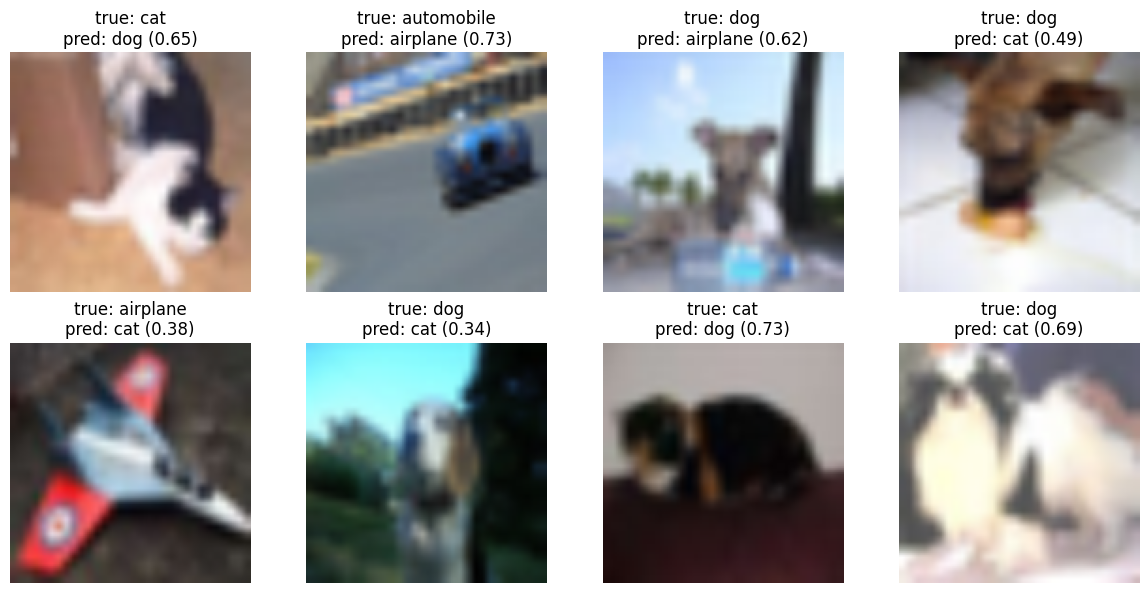

In [ ]:
mis_idx = np.flatnonzero(y_true != y_pred)

print("Number of test errors:", len(mis_idx))

if len(mis_idx) == 0:
    print("No errors found on this subset. Increase TEST_PER_CLASS or use a harder class set.")
else:
    n_show = min(8, len(mis_idx))
    selected = mis_idx[:n_show]

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.ravel()

    for ax_i, test_position in enumerate(selected):
        image, true_label = test_ds[int(test_position)]
        pred_label = int(y_pred[test_position])
        confidence = float(y_prob[test_position, pred_label])

        axes[ax_i].imshow(denormalize(image).permute(1, 2, 0).numpy())
        axes[ax_i].set_title(
            f"true: {SELECTED_CLASS_NAMES[true_label]}\n"
            f"pred: {SELECTED_CLASS_NAMES[pred_label]} ({confidence:.2f})"
        )
        axes[ax_i].axis("off")

    for j in range(n_show, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# Part 8 — Concept checks

### Q1
Why can the same convolution kernel detect a similar pattern at different image positions?

### Q2
What is the difference between a kernel, a feature map, and a channel?

### Q3
If a \(32\times32\) input uses a \(3\times3\) kernel, padding 1, and stride 2, what is the output spatial size?

### Q4
Why did we freeze most of MobileNetV3 before fine-tuning?

### Q5
Why should the test set not be checked after every training epoch?

### Q6
What does macro-F1 tell us that a single accuracy number may hide?

### Q7
Why can two models with similar GFLOPs still have different inference latency?

### Trả lời Concept checks

**Q1.** Nhờ **weight sharing**: cùng một bộ trọng số kernel được trượt qua mọi vị trí trên ảnh, và ở mỗi vị trí nó tính cùng một phép nhân–cộng trên patch cục bộ. Vì vậy, pattern nào làm kernel phản ứng mạnh ở góc trái thì cũng làm kernel phản ứng mạnh ở góc phải. Phép convolution có tính **equivariant** với phép tịnh tiến: dịch input bao nhiêu thì feature map dịch theo bấy nhiêu.

**Q2.**
- **Kernel (filter):** tập trọng số học được, kích thước $C_{in} \times k \times k$.
- **Feature map:** output 2D thu được khi áp **một** kernel lên toàn bộ input.
- **Channel:** một "lớp" dọc theo chiều độ sâu của tensor. Ở input, channel là R, G, B. Ở các layer sau, mỗi channel chính là một feature map, nên số channel output bằng số kernel.

**Q3.** $N_{out} = \lfloor (32 + 2\cdot1 - 3)/2 \rfloor + 1 = \lfloor 15.5 \rfloor + 1 = $ **16**, tức output có kích thước $16 \times 16$.

**Q4.** Vì dữ liệu ít (2.000 ảnh train). Backbone được pretrain trên ImageNet đã học sẵn các đặc trưng tổng quát: cạnh, texture, hình dạng. Đóng băng backbone giúp:
- tránh phá hỏng các đặc trưng này bằng gradient nhiễu từ head còn đang ở trạng thái ngẫu nhiên;
- giảm overfit, vì số tham số phải học ít hơn nhiều;
- train nhanh hơn và tốn ít bộ nhớ hơn.

Sau khi head đã ổn định, ta mới mở dần các block cuối với learning rate nhỏ.

**Q5.** Nếu dùng test set sau mỗi epoch để chọn epoch hay hyperparameter, test set sẽ trở thành một validation set thứ hai. Khi đó ta đã gián tiếp "fit" theo test set, và điểm số báo cáo sẽ lạc quan hơn thực tế, không còn là ước lượng không thiên lệch cho dữ liệu mới. Mọi lựa chọn nên dựa trên validation set, còn test set chỉ dùng **một lần** ở cuối.

**Q6.** Macro-F1 tính F1 riêng cho từng lớp rồi lấy trung bình với trọng số như nhau, nên một lớp làm kém sẽ kéo điểm xuống rõ ràng. Accuracy thì bị chi phối bởi các lớp đông mẫu: một model bỏ qua gần hết lớp thiểu số vẫn có thể đạt accuracy cao (xem Exercise 4). Macro-F1 cũng phản ánh cân bằng giữa precision và recall, không chỉ đếm số dự đoán đúng.

**Q7.** GFLOPs chỉ đếm số phép toán, không phản ánh:
- **truy cập bộ nhớ** (memory bandwidth), ví dụ depthwise conv có ít FLOPs nhưng bị giới hạn bởi bộ nhớ;
- **mức độ song song hóa** trên phần cứng;
- **số lượng layer và kernel launch** (nhiều layer nhỏ gây overhead);
- các phép toán không tính vào FLOPs như activation, reshape, concat;
- **mức tối ưu** của thư viện, phần cứng (CPU hay GPU), batch size và kiểu dữ liệu.

Vì vậy hai model có GFLOPs gần nhau vẫn có thể chạy nhanh chậm rất khác nhau.


# Part 9 — Exercises

## Exercise 1 — Build your own kernel

Create a \(3\times3\) filter that responds to a horizontal edge.

Apply it to `img_tensor` using `F.conv2d` and visualize the result.

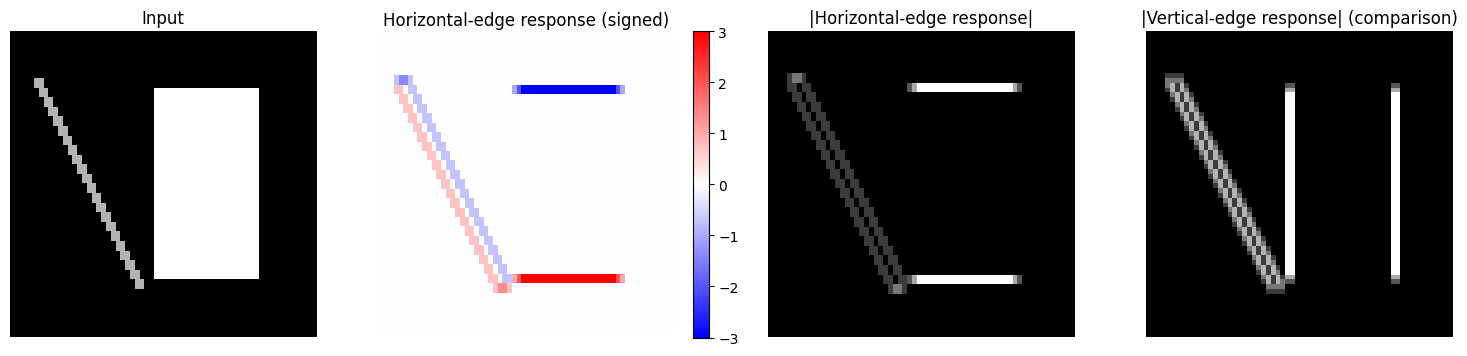

Response range: -3.0 to 3.0
Rows with the strongest response: [12, 11, 52, 51]
Response at rectangle's top edge (row 11):    [-3.0, -3.0, -3.0]
Response at rectangle's bottom edge (row 52): [3.0, 3.0, 3.0]
Response at rectangle's left edge (row 30, cols 28-31): [0.0, 0.0, 0.0, 0.0]


In [ ]:
# Exercise 1: horizontal-edge kernel (Prewitt, top row minus bottom row)
my_kernel = torch.tensor([
    [ 1.,  1.,  1.],
    [ 0.,  0.,  0.],
    [-1., -1., -1.],
], dtype=torch.float32)[None, None]

my_output = F.conv2d(img_tensor, my_kernel, padding=1)[0, 0]

vertical_kernel = my_kernel[0, 0].T[None, None]    # same kernel rotated -> vertical edges
vertical_output = F.conv2d(img_tensor, vertical_kernel, padding=1)[0, 0]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("Input")
im = axes[1].imshow(my_output.numpy(), cmap="bwr", vmin=-3, vmax=3); axes[1].set_title("Horizontal-edge response (signed)")
axes[2].imshow(my_output.abs().numpy(), cmap="gray"); axes[2].set_title("|Horizontal-edge response|")
axes[3].imshow(vertical_output.abs().numpy(), cmap="gray"); axes[3].set_title("|Vertical-edge response| (comparison)")
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

row_strength = my_output.abs().sum(dim=1)
print("Response range:", my_output.min().item(), "to", my_output.max().item())
print("Rows with the strongest response:", row_strength.argsort(descending=True)[:4].tolist())
print("Response at rectangle's top edge (row 11):   ", my_output[11, 32:35].tolist())
print("Response at rectangle's bottom edge (row 52):", my_output[52, 32:35].tolist())
print("Response at rectangle's left edge (row 30, cols 28-31):", my_output[30, 28:32].tolist())


**Answer (Exercise 1):** Kernel lấy tổng hàng trên trừ tổng hàng dưới, nên chỉ phản ứng khi độ sáng thay đổi **theo chiều dọc**, tức là tại cạnh nằm ngang.

- **Cạnh trên** của hình chữ nhật (tối → sáng khi đi xuống) cho giá trị **−3**. **Cạnh dưới** (sáng → tối) cho **+3**. Dấu cho biết hướng chuyển độ sáng.
- Ở **cạnh trái/phải** của hình chữ nhật, response bằng **0**, vì trên cột đó hàng trên và hàng dưới sáng như nhau.
- Đường chéo dốc chỉ cho response yếu. So với kernel dọc, kết quả ngược lại.
- Vùng phẳng (toàn đen hoặc toàn trắng) cũng cho **0**.

Như vậy, một kernel 3×3 cố định đã hoạt động như một bộ phát hiện đặc trưng cục bộ.


## Exercise 2 — Predict the shape before running code

For:

```text
input = 8 × 3 × 64 × 64
Conv2d(3, 32, kernel_size=5, stride=2, padding=2)
```

Predict the full output shape, then verify it with PyTorch.

In [ ]:
# Exercise 2: predict first, then verify
# Prediction: N_out = floor((64 + 2*2 - 5) / 2) + 1 = floor(31.5) + 1 = 32
#             channels = number of kernels = 32, batch unchanged = 8
predicted_hw = conv_output_size(64, kernel_size=5, padding=2, stride=2)
predicted_shape = (8, 32, predicted_hw, predicted_hw)
print("Predicted shape:", predicted_shape)

layer = nn.Conv2d(3, 32, kernel_size=5, stride=2, padding=2)
x = torch.randn(8, 3, 64, 64)
y = layer(x)
print("PyTorch shape:  ", tuple(y.shape))
assert tuple(y.shape) == predicted_shape

n_params = sum(p.numel() for p in layer.parameters())
print("Layer parameters:", n_params, "= 32*3*5*5 weights + 32 biases =", 32 * 3 * 5 * 5 + 32)


Predicted shape: (8, 32, 32, 32)
PyTorch shape:   (8, 32, 32, 32)
Layer parameters: 2432 = 32*3*5*5 weights + 32 biases = 2432


**Answer (Exercise 2):** Output có shape **8 × 32 × 32 × 32**.

- **Batch** giữ nguyên là 8.
- **Channel** = số kernel = 32.
- **Kích thước không gian:** $\lfloor (64 + 2\cdot2 - 5)/2 \rfloor + 1 = \lfloor 31.5 \rfloor + 1 = 32$. Stride 2 làm giảm một nửa chiều cao và chiều rộng. Padding 2 với kernel 5 giữ "same" nếu stride là 1.
- Layer có $32 \cdot 3 \cdot 5 \cdot 5 + 32 = 2432$ tham số, và con số này không phụ thuộc vào kích thước ảnh.


## Exercise 3 — More fine-tuning

Change exactly one variable:

- unfreeze more feature blocks; or
- increase fine-tuning epochs; or
- change the backbone learning rate.

Before running, write a hypothesis:

> I expect validation macro-F1 to ______ because ______.

Do not use the test set to choose the setting.

### Helper for Exercises 3–5

`train_cnn` repeats the exact pipeline of Part 4: a new pretrained MobileNetV3-Small → Phase A trains only the head → Phase B unfreezes the last `unfreeze_blocks` blocks. It returns the model with the best **validation** macro-F1. Each run resets the seed, so runs can be compared fairly with each other.


In [ ]:
def make_loader(dataset, shuffle):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
    )


def train_cnn(train_loader_, val_loader_=None, unfreeze_blocks=3, head_epochs=HEAD_EPOCHS,
              finetune_epochs=FINETUNE_EPOCHS, backbone_lr=1e-4, seed=SEED, tag=""):
    val_loader_ = val_loader_ or val_loader
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    m = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    for p in m.parameters():
        p.requires_grad = False
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, len(SELECTED_CLASS_NAMES))
    m = m.to(device)

    hist, best_f1, best = [], -1.0, copy.deepcopy(m.state_dict())
    start = time.perf_counter()

    def log_epoch(phase, epoch, optimizer):
        nonlocal best_f1, best
        tr = run_epoch(m, train_loader_, optimizer=optimizer)
        va = run_epoch(m, val_loader_, optimizer=None)
        hist.append({"phase": phase, "epoch": epoch, "train_loss": tr["loss"], "val_loss": va["loss"],
                     "val_acc": va["accuracy"], "val_macro_f1": va["macro_f1"]})
        print(f"[{tag}] {phase} epoch {epoch} | train loss={tr['loss']:.4f} | "
              f"val loss={va['loss']:.4f}, val F1={va['macro_f1']:.3f}")
        if va["macro_f1"] > best_f1:
            best_f1, best = va["macro_f1"], copy.deepcopy(m.state_dict())

    # Phase A: head only
    opt_a = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=3e-3, weight_decay=1e-4)
    for epoch in range(1, head_epochs + 1):
        log_epoch("head", epoch, opt_a)

    # Phase B: unfreeze the last blocks + classifier
    for block in m.features[-unfreeze_blocks:]:
        for p in block.parameters():
            p.requires_grad = True
    for p in m.classifier.parameters():
        p.requires_grad = True
    opt_b = torch.optim.AdamW(
        [
            {"params": [p for p in m.features.parameters() if p.requires_grad], "lr": backbone_lr},
            {"params": [p for p in m.classifier.parameters() if p.requires_grad], "lr": 5e-4},
        ],
        weight_decay=1e-4,
    )
    for epoch in range(1, finetune_epochs + 1):
        log_epoch("fine-tune", epoch, opt_b)

    m.load_state_dict(best)
    info = {
        "setting": tag,
        "best_val_macro_f1": best_f1,
        "trainable_params": sum(p.numel() for p in m.parameters() if p.requires_grad),
        "train_seconds": time.perf_counter() - start,
    }
    return m, info, pd.DataFrame(hist)


def evaluate_on(model_, loader_):
    y_t, y_p, _ = predict_loader(model_, loader_)
    _, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
        y_t, y_p, labels=list(range(len(SELECTED_CLASS_NAMES))), zero_division=0
    )
    row = {
        "accuracy": accuracy_score(y_t, y_p),
        "macro_f1": f1_score(y_t, y_p, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_t, y_p, average="weighted", zero_division=0),
    }
    for name, r in zip(SELECTED_CLASS_NAMES, recall_per_class):
        row[f"recall_{name}"] = r
    return row


**Biến được thay đổi:** số block được mở băng, **3 → 6**. Các yếu tố khác giữ nguyên: số epoch, learning rate, dữ liệu và seed.

**Giả thuyết:** Tôi dự đoán validation macro-F1 sẽ **tăng nhẹ**, vì mở thêm block giúp model thích nghi tốt hơn với ảnh CIFAR (ảnh nhỏ 32×32 được phóng to, khác với ảnh ImageNet). Tuy nhiên, với chỉ 2.000 ảnh train và 2 epoch fine-tune, mức cải thiện có thể nhỏ. Cũng có rủi ro overfit, vì số tham số được train tăng lên.

Chỉ dùng **validation set** để so sánh hai cấu hình. Không dùng test set ở bài này.


In [ ]:
ex3_baseline_model, ex3_baseline_info, ex3_baseline_hist = train_cnn(train_loader, unfreeze_blocks=3, tag="unfreeze 3 (baseline)")
ex3_more_model, ex3_more_info, ex3_more_hist = train_cnn(train_loader, unfreeze_blocks=6, tag="unfreeze 6")

ex3_results = pd.DataFrame([ex3_baseline_info, ex3_more_info])
display(ex3_results.round(4))

# Also compare the validation curves across epochs
display(pd.concat([
    ex3_baseline_hist.assign(setting="unfreeze 3"),
    ex3_more_hist.assign(setting="unfreeze 6"),
]).pivot_table(index=["phase", "epoch"], columns="setting", values="val_macro_f1", sort=False).round(4))


[unfreeze 3 (baseline)] head epoch 1 | train loss=0.5248 | val loss=0.3856, val F1=0.839
[unfreeze 3 (baseline)] fine-tune epoch 1 | train loss=0.3752 | val loss=0.4242, val F1=0.826
[unfreeze 3 (baseline)] fine-tune epoch 2 | train loss=0.2409 | val loss=0.4097, val F1=0.824
[unfreeze 6] head epoch 1 | train loss=0.5248 | val loss=0.3856, val F1=0.839
[unfreeze 6] fine-tune epoch 1 | train loss=0.4145 | val loss=0.5215, val F1=0.775
[unfreeze 6] fine-tune epoch 2 | train loss=0.2486 | val loss=0.5069, val F1=0.805


,setting,best_val_macro_f1,trainable_params,train_seconds
0,unfreeze 3 (baseline),0.8394,1239588,9.1746
1,unfreeze 6,0.8394,1383204,9.3948


setting          unfreeze 3  unfreeze 6
phase     epoch                        
head      1          0.8394      0.8394
fine-tune 1          0.8265      0.7746
          2          0.8237      0.8051

**Answer (Exercise 3):** Giả thuyết **không được xác nhận**. Mở thêm block không làm validation macro-F1 tăng, mà còn làm kết quả fine-tune kém đi.

- Cả hai cấu hình có cùng `best_val_macro_f1 = 0.8394`, nhưng đây là điểm **sau Phase A**. Phase A chỉ train head, và vì cùng seed nên hai cấu hình giống hệt nhau ở bước này. Ở cả hai cấu hình, Phase B đều không vượt được mốc đó, nên con số "best" không phân biệt được hai cấu hình. Muốn so sánh phải nhìn vào các epoch fine-tune.
- Trong Phase B, mở 6 block cho **val F1 thấp hơn** (0.775 → 0.805, so với 0.826 → 0.824 của baseline) và **val loss cao hơn** (0.52 / 0.51 so với 0.42 / 0.41).
- Trong khi đó train loss vẫn giảm tới mức tương đương (0.249 so với 0.241). Train loss giảm nhưng val loss tăng là **dấu hiệu overfit**: có thêm ≈144k tham số được train (1.24M → 1.38M), nhưng chỉ có 2.000 ảnh train.
- Thời gian train gần như bằng nhau (9.2 s so với 9.4 s trên T4).
- Hiện tượng tương tự cũng xuất hiện ở lần chạy chính của Part 4: val F1 tốt nhất là 0.858 ngay sau Phase A, còn fine-tune chỉ đạt 0.840 / 0.834. Với lượng dữ liệu này, mở nhiều block hơn là không có lợi. Tuy nhiên đây mới là kết quả của một seed, cần chạy nhiều seed để kết luận chắc chắn.


## Exercise 4 — Accuracy vs macro-F1

Create an imbalanced training subset, for example:

```text
airplane:   500
automobile: 500
cat:        500
dog:         80
```

Compare accuracy, dog recall, macro-F1, and weighted-F1.

**Question:** can accuracy look acceptable while one class performs poorly?

**Setup:** keep all 500 images for airplane, automobile, and cat, but only **80 images for dog**. Validation stays balanced. Evaluate on two test sets:

1. the **balanced** test set from Part 5 (200 images per class);
2. an **imbalanced** test set with the same ratio as the training data (200 / 200 / 200 / 32 dogs), which is closer to reality when the dog class is rare.

For comparison, the model trained on balanced data is `ex3_baseline_model` from Exercise 3.


In [ ]:
DOG_ID = SELECTED_CLASS_IDS[SELECTED_CLASS_NAMES.index("dog")]
train_targets_all = np.asarray(raw_train.targets)
test_targets_all = np.asarray(raw_test.targets)


def take_per_class(indices, targets, limits):
    counts, kept = {}, []
    for i in indices:
        c = int(targets[i])
        if counts.get(c, 0) < limits[c]:
            kept.append(i)
            counts[c] = counts.get(c, 0) + 1
    return kept


imb_train_limits = {c: TRAIN_PER_CLASS for c in SELECTED_CLASS_IDS}
imb_train_limits[DOG_ID] = 80
imb_train_indices = take_per_class(train_indices, train_targets_all, imb_train_limits)

imb_test_limits = {c: TEST_PER_CLASS for c in SELECTED_CLASS_IDS}
imb_test_limits[DOG_ID] = round(TEST_PER_CLASS * 80 / TRAIN_PER_CLASS)   # 32
imb_test_indices = take_per_class(test_indices, test_targets_all, imb_test_limits)

imb_train_loader = make_loader(RemappedSubset(train_base, imb_train_indices, label_map), shuffle=True)
imb_test_loader = make_loader(RemappedSubset(test_base, imb_test_indices, label_map), shuffle=False)

print("Imbalanced train counts:", pd.Series(train_targets_all[imb_train_indices]).map(dict(zip(SELECTED_CLASS_IDS, SELECTED_CLASS_NAMES))).value_counts().to_dict())
print("Imbalanced test counts: ", pd.Series(test_targets_all[imb_test_indices]).map(dict(zip(SELECTED_CLASS_IDS, SELECTED_CLASS_NAMES))).value_counts().to_dict())

ex4_imb_model, ex4_imb_info, _ = train_cnn(imb_train_loader, unfreeze_blocks=3, tag="imbalanced train (dog=80)")

ex4_rows = []
for train_name, m_ in [("balanced train", ex3_baseline_model), ("imbalanced train (dog=80)", ex4_imb_model)]:
    for test_name, loader_ in [("balanced test", test_loader), ("imbalanced test (dog=32)", imb_test_loader)]:
        ex4_rows.append({"train": train_name, "test": test_name, **evaluate_on(m_, loader_)})

ex4_results = pd.DataFrame(ex4_rows)
ex4_results[["train", "test", "accuracy", "recall_dog", "macro_f1", "weighted_f1",
             "recall_airplane", "recall_automobile", "recall_cat"]].round(4)


Imbalanced train counts: {'cat': 500, 'airplane': 500, 'automobile': 500, 'dog': 80}
Imbalanced test counts:  {'cat': 200, 'automobile': 200, 'airplane': 200, 'dog': 32}
[imbalanced train (dog=80)] head epoch 1 | train loss=0.4790 | val loss=0.5322, val F1=0.755
[imbalanced train (dog=80)] fine-tune epoch 1 | train loss=0.3022 | val loss=0.4590, val F1=0.794
[imbalanced train (dog=80)] fine-tune epoch 2 | train loss=0.1660 | val loss=0.5197, val F1=0.788


,train,test,accuracy,recall_dog,macro_f1,weighted_f1,recall_airplane,recall_automobile,recall_cat
0,balanced train,balanced test,0.8475,0.7950,0.8472,0.8472,0.920,0.945,0.730
1,balanced train,imbalanced test (dog=32),0.8639,0.8438,0.7977,0.8743,0.920,0.945,0.730
2,imbalanced train (dog=80),balanced test,0.8412,0.6250,0.8371,0.8371,0.915,0.980,0.845
3,imbalanced train (dog=80),imbalanced test (dog=32),0.8956,0.5625,0.8236,0.8953,0.915,0.980,0.845


**Answer (Exercise 4):** **Có.** Accuracy có thể trông tốt, thậm chí tốt hơn, trong khi một lớp bị làm rất kém.

- **Dog recall giảm mạnh** khi chỉ train với 80 ảnh chó:
  - trên test set cân bằng: 0.795 → **0.625**;
  - trên test set mất cân bằng: 0.844 → **0.5625**, tức chỉ nhận đúng 18 / 32 ảnh chó.
- Trên **test set mất cân bằng**, model train lệch có **accuracy 0.896** và **weighted-F1 0.895**. Đây là **cao nhất bảng**, cao hơn cả model train cân bằng (0.864 / 0.874). Trong khi đó dog recall chỉ đạt 0.56, và **macro-F1 chỉ 0.824**.
  - Lý do: chó chỉ chiếm 32 / 632 ≈ 5% test set, nên đoán sai nhiều ảnh chó hầu như không ảnh hưởng tới accuracy. Weighted-F1 tính trọng số theo số mẫu của từng lớp nên cũng bị che giống vậy. Macro-F1 coi mọi lớp như nhau nên mới để lộ vấn đề.
- Model bị lệch về các lớp đông mẫu: **cat recall tăng** từ 0.73 lên 0.845, automobile tăng từ 0.945 lên 0.98. Nhiều khả năng các ảnh chó bị đoán thành mèo, vì đây là lớp giống chó nhất. Để khẳng định cần xem confusion matrix.
- Trên test set cân bằng, weighted-F1 bằng đúng macro-F1, vì mọi lớp có số mẫu như nhau.


## Exercise 5 — Compute trade-off

Run the same model with:

```text
IMAGE_SIZE = 96
IMAGE_SIZE = 128
IMAGE_SIZE = 160
```

Measure GMACs, approximate GFLOPs, and latency.

Explain why spatial resolution affects computation.

Use the fine-tuned `model` from Part 4 (MobileNetV3 ends with adaptive pooling, so it accepts different input sizes). For each `IMAGE_SIZE`, measure GMACs/GFLOPs with `thop`, batch-1 latency on the current device, and test accuracy (resize the test images to that size). The model was fine-tuned at 128 px, so the accuracy at other sizes is for reference only.


,IMAGE_SIZE,pixels_vs_128,GMACs,approx_GFLOPs,median_latency_ms,p90_latency_ms,test_accuracy,test_macro_f1,GMACs_vs_128
0,96,0.5625,0.0121,0.0243,5.2496,6.7200,0.8375,0.8372,0.5847
1,128,1.0000,0.0208,0.0416,15.5636,24.3976,0.8550,0.8554,1.0000
2,160,1.5625,0.0319,0.0637,16.7560,27.8116,0.8962,0.8960,1.5339


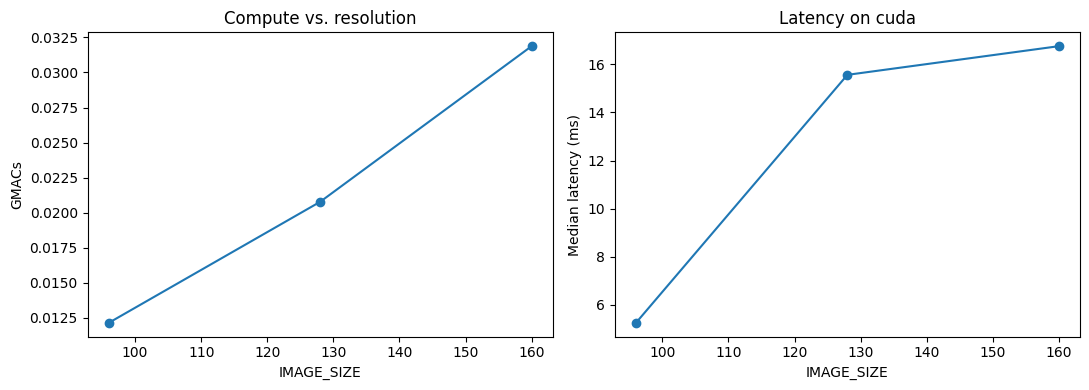

In [41]:
ex5_rows = []
for size in [96, 128, 160]:
    prof_model = copy.deepcopy(model).cpu().eval()
    macs_s, _ = profile(prof_model, inputs=(torch.randn(1, 3, size, size),), verbose=False)

    lat = measure_latency(model, image_size=size)

    size_transform = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    size_test_base = datasets.CIFAR10(root="./data", train=False, transform=size_transform, download=False)
    size_loader = make_loader(RemappedSubset(size_test_base, test_indices, label_map), shuffle=False)
    size_metrics = evaluate_on(model, size_loader)

    ex5_rows.append({
        "IMAGE_SIZE": size,
        "pixels_vs_128": (size / 128) ** 2,
        "GMACs": macs_s / 1e9,
        "approx_GFLOPs": 2 * macs_s / 1e9,
        "median_latency_ms": np.median(lat),
        "p90_latency_ms": np.percentile(lat, 90),
        "test_accuracy": size_metrics["accuracy"],
        "test_macro_f1": size_metrics["macro_f1"],
    })

ex5_results = pd.DataFrame(ex5_rows)
ex5_results["GMACs_vs_128"] = ex5_results["GMACs"] / ex5_results.loc[ex5_results["IMAGE_SIZE"] == 128, "GMACs"].item()
display(ex5_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ex5_results["IMAGE_SIZE"], ex5_results["GMACs"], marker="o")
axes[0].set_xlabel("IMAGE_SIZE"); axes[0].set_ylabel("GMACs"); axes[0].set_title("Compute vs. resolution")
axes[1].plot(ex5_results["IMAGE_SIZE"], ex5_results["median_latency_ms"], marker="o")
axes[1].set_xlabel("IMAGE_SIZE"); axes[1].set_ylabel("Median latency (ms)"); axes[1].set_title(f"Latency on {device}")
plt.tight_layout()
plt.show()


**Answer (Exercise 5):**

**Chi phí tính toán tăng gần như tỉ lệ với số pixel.**

| IMAGE_SIZE | pixels (so với 128) | GMACs | GMACs (so với 128) |
|---|---|---|---|
| 96 | 0.5625× | 0.0121 | 0.585× |
| 128 | 1× | 0.0208 | 1× |
| 160 | 1.5625× | 0.0319 | 1.534× |

- Lý do: mỗi layer convolution được tính tại mọi vị trí $(h, w)$ của feature map, nên số MACs tỉ lệ với $H \times W$.
- Tỉ lệ GMACs không khớp tuyệt đối với tỉ lệ pixel, vì có những phần không phụ thuộc độ phân giải. Ví dụ, classifier sau global pooling luôn tốn ≈0.6M MACs. Ngoài ra, kích thước feature map sau các lớp stride bị làm tròn.
- Số tham số **không đổi** (1.52M), vì kernel dùng chung cho mọi vị trí (weight sharing).

**Latency không tăng theo GMACs.** Median latency là 5.2 ms, 15.6 ms và 16.8 ms:
- Từ 128 lên 160, GMACs tăng 53% nhưng latency chỉ tăng ≈8%.
- Cùng kích thước 128, latency đo ở Part 5 là 7.3 ms, nhưng ở đây lên tới 15.6 ms. p90 cũng cao (24–28 ms).

Với batch 1 trên GPU T4, thời gian chủ yếu đến từ chi phí cố định (kernel launch, đồng bộ CPU–GPU), và GPU dùng chung trên Colab gây nhiễu lớn. Vì vậy GFLOPs không dự đoán tốt được latency (đúng như Q7). Muốn đo chính xác cần nhiều lần lặp hơn, hoặc đo trên thiết bị triển khai thật.

**Accuracy:** 0.838 (96), 0.855 (128) và 0.896 (160).
- Dù model chỉ được fine-tune ở 128, input lớn hơn vẫn cho accuracy cao hơn. Lý do có thể là feature map lớn hơn (5×5 thay vì 4×4 ở layer cuối) gần với tỉ lệ ảnh 224 px mà backbone được pretrain trên ImageNet.
- Đây là quan sát trên test set từ một lần chạy. Nếu muốn **chọn** IMAGE_SIZE thì phải so sánh bằng validation set, sau đó train lại ở kích thước đã chọn.

**Trade-off:** 160 px tốn thêm ≈53% phép tính nhưng tăng accuracy ≈4 điểm. 96 px tiết kiệm ≈42% phép tính nhưng mất ≈2 điểm accuracy.


# Part 10 — Takeaways

1. **Convolution is local.**
2. **Weights are shared across positions.**
3. **Many kernels create many feature maps.**
4. **ReLU adds nonlinearity.**
5. **Pooling or strided layers reduce spatial resolution.**
6. **Deeper CNN layers combine increasingly broad context.**
7. **Transfer learning reuses pretrained visual features.**
8. **Fine-tuning adapts pretrained weights to a new task.**
9. **Evaluation requires more than accuracy.**
10. **Efficiency requires more than parameter count.**

---

## References

- PyTorch / TorchVision — Models and pretrained weights:  
  https://docs.pytorch.org/vision/main/models
- TorchVision — CIFAR-10 dataset:  
  https://docs.pytorch.org/vision/main/datasets.html
- TorchVision — MobileNetV3-Small:  
  https://docs.pytorch.org/vision/main/models/generated/torchvision.models.mobilenet_v3_small.html
- Howard et al., *Searching for MobileNetV3* (2019):  
  https://arxiv.org/abs/1905.02244
- scikit-learn — F1 score:  
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html
- scikit-learn — Confusion matrix:  
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
- THOP — PyTorch MAC/parameter profiler:  
  https://github.com/ultralytics/thop

### Note on operation counts

THOP reports **MACs**. This notebook additionally reports approximately $2\times$ MACs as FLOPs under the convention that a multiplication and an addition are two floating-point operations. Other papers/tools may use another convention, so always state the profiler, input size, and counting rule.